In [20]:
import librosa 
import soundfile as sf
import sounddevice as sd
import time 
path="D:/KARAOKE-main/KARAOKE-main/songlib/jailer2.mp3" 
#y,sr=librosa.load(path,sr=None,mono=True)
y,sr=sf.read(path)
print("Sample rate",sr,"hz")
print("Duration",len(y)/sr)
print('Number of samples ',len(y))
print("shape",y.shape)
#print(sd.query_devices())
sd.play(y[sr*30:sr*60],sr)
#time.sleep(5)
sd.wait()




Sample rate 44100 hz
Duration 107.5568253968254
Number of samples  4743256
shape (4743256, 2)


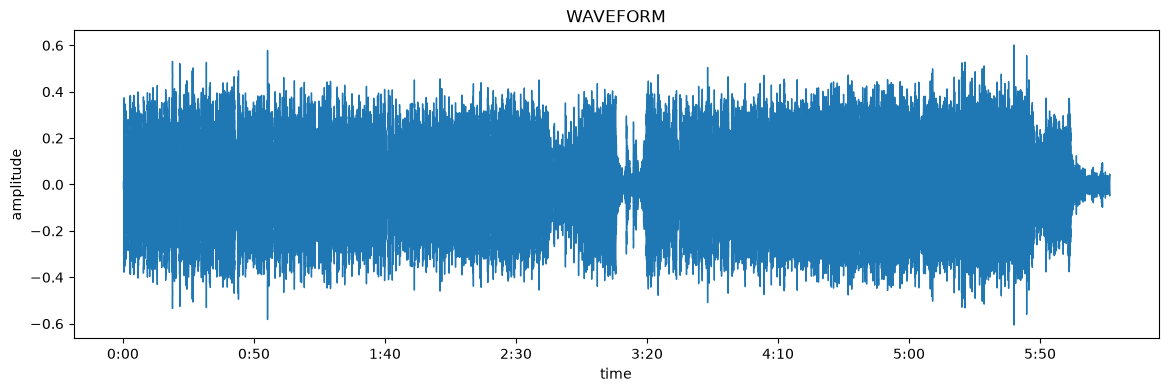

0.6036496 9.313226e-10 0.07054253


In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.figure(figsize=(14,4))
librosa.display.waveshow(y,sr=sr)
plt.title('WAVEFORM')
plt.xlabel('time')
plt.ylabel('amplitude')
plt.show()
print(np.abs(y).max(),np.abs(y).min(),np.abs(y).mean())

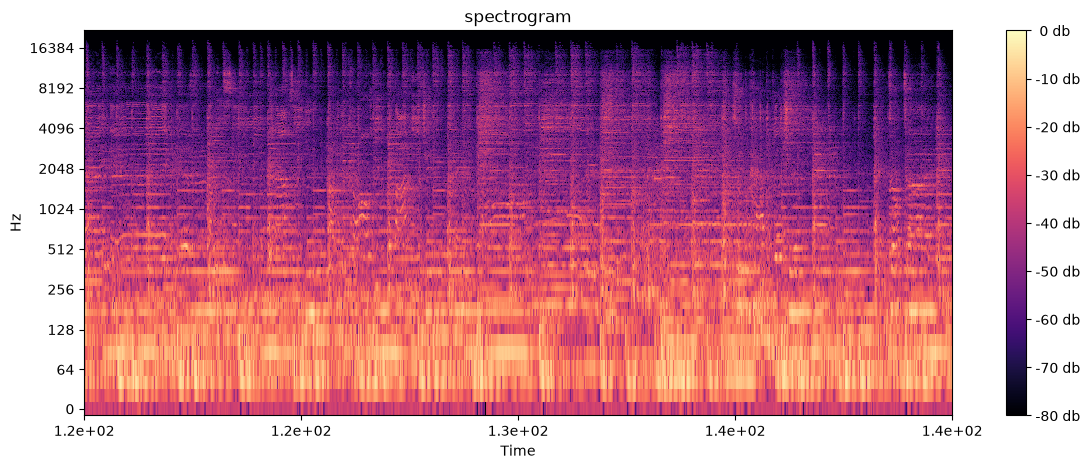

In [3]:
#SPECTROGRAM
d=librosa.stft(y)
#STFT
#convert amplitude into decibels
db=librosa.amplitude_to_db(np.abs(d),ref=np.max)
plt.figure(figsize=(14,5))
librosa.display.specshow(db,sr=sr,y_axis='log',x_axis='time')
plt.colorbar(format='%2.0f db')
plt.xlim(120,140)
plt.title('spectrogram')
plt.show()


In [ ]:
from scipy.signal import butter, sosfilt

def bandpass(y, sr, low, high):
    sos = butter(4, [low, high], btype='band', fs=sr, output='sos')
    return sosfilt(sos, y)

# test your bass hypothesis
bass_guess = bandpass(y, sr, 40, 150)
# save it and listen
import soundfile as sf
sf.write("bass_guess.wav", bass_guess, sr)
#vibecoded-save


In [4]:
import soundfile as sf 
import numpy as np
right=y[1]
left=y[0]
instrumental=right-left
sf.write("Phase_cancel_puma.wav",instrumental,sr)#DONT run again saved file is present in main/induvidual


IndexError: tuple index out of range

In [ ]:
#PHASING different types
y,r=librosa.load("BORDERLINE.mp3",sr=sr,duration=20)
D=librosa.stft(y)
mag=np.abs(D)
phase=np.angle(D)

y_true = librosa.istft(mag * np.exp(1j * phase))#off phase
sf.write("true_phase.wav",y_true,sr)

y_zero = librosa.istft(mag.astype(complex))
sf.write("recon_zero_phase.wav", y_zero, sr)  #bad timing

In [3]:
#DEMUCS AUDIO SEPRATION
import subprocess
import sys
from pathlib import Path
import argparse

#udf
def separate(song_path,out_path="output"):
    song=Path(song_path)
    if not song.exists():
        raise FileNotFoundError(f"Cant find {song}")
    demucs_out=Path(out_path) / "_demucs_raw"
    #demucs cmd
    cmd=[sys.executable,"-m",'demucs','--two-stems=vocals','-o',str(out_path),str(song)]
    subprocess(cmd, check=True)




    if __name__=="__main__":
        pr1=argparse.ArgumentParser(description="outputchar")
        pr1.add_argument("song")
        pr1.add_argument("--out",default="output")
        args=pr1.parse_args()
        
        separate(args.song,args.out)
    

In [1]:
import time
import sounddevice as sd
import soundfile  as sf
data , sr =sf.read("D:/KARAOKE-main/KARAOKE-main/songlib/BORDERLINE.mp3")
channels=data.shape[1]
pos=0
def callback(outdata,frames,time_info,status):
    global pos
    chunk=data[pos:pos+frames]
    if len(chunk)<frames:
        outdata[:len(chunk)]=chunk
        outdata[len(chunk):]=0
        raise sd.CallbackStop
    outdata[:]=chunk
    pos=pos+frames
player=sd.OutputStream(samplerate=sr,channels=channels,callback=callback)
player.start()
time.sleep(10)
player.stop()
player.close()


1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136
1136


In [ ]:
import numpy as np
import sounddevice as sd
import soundfile as sf
import time
pos=0
vocals,sr1=sf.read("D:/KARAOKE-main/KARAOKE-main/output/_demucs_raw/htdemucs/jailer2/vocals_jailer.wav",dtype="float32")
instr,sr2=sf.read("D:/KARAOKE-main/KARAOKE-main/output/_demucs_raw/htdemucs/jailer2/no_vocals_jailer.wav",dtype="float32")
channels=vocals.shape[1]
if sr1==sr2 and vocals.shape[0]==instr.shape[0]:
    only_voc=1.0
    ins_vol=1.0
    print(sr1,sr2)
    print(vocals.shape,instr.shape)
    def callback(outdata,frames,time_info,status):
        global pos
        vocal_chunk=vocals[pos:pos+frames]
        instr_chunk=instr[pos:pos+frames]
        mix=vocal_chunk*only_voc+instr_chunk*ins_vol
        mix=np.clip(mix,-1,1)
        if len(mix)<frames:
            outdata[:len(mix)]=mix
            outdata[len(mix):]=0
            raise sd.CallbackStop
        outdata[:]=mix
        pos=pos+frames
        pass
player=sd.OutputStream(samplerate=sr1,channels=channels,callback=callback)
player.start()
time.sleep(20)
player.stop()
player.close()
        


44100 44100
(4745088, 2) (4745088, 2)
